# Map 2 — SectorDrop / rank-MUSIC / LOS-only NTN

Uses the deployment, rank-MUSIC, multipath, and beamforming implementations from `Nulling_CDF_SectorDrop.ipynb`, running **one scene, one frequency case, and one scheduling round**.

- **50 NTN-UEs**, initially sampled as 70% rooftop / 30% outdoor (35 rooftop / 15 outdoor before the central exclusion; the existing 80%/20% refill can change final counts); **12 TN-UEs**, one per sector of each BS, each with 50% outdoor probability rather than a fixed 6/6 split. Association margins and candidate retry rules match the main notebook.
- BS height is **40 m above the local ground/roof**, with **2 degree panel downtilt** as a geometry-based starting point for kilometer-scale links. Final beams are also steered by the precoder; this tilt is not a measured optimum for nulling.
- **Analytic covariance + rank-MUSIC**, with 6×6 spatial smoothing, forward-backward averaging, and correlated power fitting on the full array. NTN sensing and terminal channels use **LOS only (`ntn_max_depth=0`)**; blocked links have no direct path. TN channels retain **`max_depth=3`** with reflection and refraction. `pair_keys=None`.
- Defaults to the main notebook's **7 GHz reference carrier (UL offset = 0%)**. Select a single nonzero UL offset in the configuration cell if needed. There is no frequency sweep or activity-probability model.
- Defaults to **λ = 10¹⁵**. The maps use nulling beams computed from estimated directions and powers. Actual INR suppression and TN SINR changes are reported; a large λ does not eliminate estimation error.
- Displays only **detected NTN-UEs** and the 12 scheduled TN-UEs. Detection markers use the main notebook's multipath angular matching (5° tolerance). Truth matching is used only for visualization, not for detection or beamforming.
- Three dashed lines from each BS mark sector boundaries at **60°, 180°, and 300° + yaw**, clipped to that BS's rectangular region, matching the TN sampler.

Use the **Python (sionna22)** kernel and run the cells in order. The import cell explicitly selects and checks the CUDA backend before loading Sionna or creating scene objects. Restart the kernel after a CUDA out-of-memory failure. Random seed controls default to `None` for fresh runs; each before/after radio-map pair shares one seed. The single scene includes normal TN association retries. Outputs are saved separately under `result/map/<timestamp>/`, using America/New_York time with an EDT/EST suffix.

The **terminal INR CDF** compares the same detected UEs before/after nulling, with a second panel for all 50 deployed UEs. It uses the LOS-only VSAT channels, satellite look direction, and receiver noise. Individual UE powers and paired suppression statistics are exported.

The **planar radio maps over the flat scene** use `RadioMapSolver` and `scene.render`, with **`radiomap_max_depth=3`** independent of NTN channel depth. Both maps share launch directions, interaction seeds, propagation options, camera, and color limits. Native Sionna maps average multipath powers with an isotropic receiver and use scene thermal noise; the terminal CDF evaluates LOS-only VSAT channels. Radio-map beam weights use the main experiment's conjugate-export convention. Only detected NTN-UE markers are shown. Rerun from the imports after changing propagation settings to regenerate detection, beams, and maps.

GPU defaults use **10 m cells, one billion launch directions per TX, and 2000 × 2000 render pixels**, with 3.35-inch-wide combined and standalone figures and shared 2nd/98th percentile color limits. The 12 TX are solved in twelve batches of one, with a complete one-billion-direction lattice for every TX. This keeps each solver call at one billion rays, below the sampler's uint32 count limit. Per-TX path gains are concatenated before summing RSS / noise; they are not averaged across batches. The 10 m grid uses 100 times fewer cells than the previous 1 m grid. Zero-sampled cells remain transparent; more rays reduce sampling holes but do not guarantee power in every obstructed cell. BS triangle vertices follow the three actual array boresights. BS triangles, their paired TN circle fills, and their sector boundaries share one of four BS colors. TN circles retain dark edges and a white outline; detected NTN users use smaller magenta crosses. Sector boundaries remain visible below these symbols. All radio-map parameters, solving, and rendering code live in Sections 6 and 7 below. Change the surface or ray density without repeating deployment or MUSIC; change appearance without solving again.

Active scene: `Denver_scene/10kmwithfigure/scenes/flat/scene.xml`; the 1 m ground slab has its top at z=0. The measurement plane is 1 m above ground to keep more low structures visible. The previous terrain settings remain commented in the code.

Final before/after, before-only, and after-only PNG/PDF files are saved once in the run directory. Intermediate panels stay in memory; redraw directories contain settings. A shared crop removes the white surround, and frameless colorbars sit close to each map.

Each full run samples fresh UE positions and saves a geographic deployment figure showing all 50 NTN UEs: detected UEs use the radiomap magenta, and undetected UEs use dark gray. The existing 2×2 BS placement is retained. Layout, CDF, radiomaps, parameters, and data snapshots all share the same timestamped run directory.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/map2-matplotlib")
import sys
import gc
import mitsuba as mi
import drjit as dr
# Select the Sionna 2.2 CUDA variant before importing Sionna or creating arrays.
if mi.variant() is None:
    mi.set_variant("cuda_ad_mono_polarized")
if mi.variant() != "cuda_ad_mono_polarized" or not dr.has_backend(dr.JitBackend.CUDA):
    raise RuntimeError("Select Python (sionna22), restart the kernel, then run from this cell with CUDA available.")
import importlib
from pathlib import Path
from datetime import datetime
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.stats import chi2
import sionna.rt as sionna_rt
from sionna.rt import load_scene
print(f"Python: {sys.executable}\nSionna RT: {sionna_rt.__version__}; Mitsuba backend: {mi.variant()}")
 
import SceneConfigSionnaSectorDrop as SceneConfigSionna
import multipath_support as mps
importlib.reload(mps)
import ntn_music_detection as nmd

importlib.reload(SceneConfigSionna)
importlib.reload(nmd)

import nulling_cdf_utils as ncu
importlib.reload(ncu)

from SceneConfigSionnaSectorDrop import SceneConfigSionna

# Public CIR helper (also re-exported by nmd); the experiment calls it internally.
from multipath_support import collapse_cir_to_narrowband

import sector_drop_reporting as reporting
importlib.reload(reporting)

import map2_support as map2
importlib.reload(map2)

plt.rcParams.update({"font.family": "serif", "font.size": 8, "pdf.fonttype": 42})


Python: /home/shizhen/miniconda3/envs/sionna22/bin/python
Sionna RT: 2.2.0; Mitsuba backend: cuda_ad_mono_polarized


## 1. Parameters (main notebook settings with overrides for UE count, one scene, and λ)

In [2]:
# Geometry and deployment
bs_height_m = 40.0  # Height above local ground, or above the roof at building sites.
ntn_rx = 50
tn_rx = 12
bs_row = 2
bs_col = 2
nbs = bs_row * bs_col
nsect = 3

# One UE per BS rectangle and horizontal sector (12 UEs total).
# Type is sampled once per region and preserved through all channel retries.
# Outdoor: ground + 1.8 m. Indoor: roof - 1.5 m.
# Mixed indoor/outdoor deployment uses the multipath settings below.
tn_outdoor_probability = 0.5
tn_association_margin_db = 3.0  # 10*log10(serving power / strongest of other 11).
tn_max_attempts = 256  # Maximum distinct grid candidates per region.
tn_candidates_per_batch = 16

# Satellite sampling configuration for Monte Carlo
satellite_resample_per_macro = True
satellite_azimuth_range_deg = (0.0, 360.0)
satellite_elevation_range_deg = (25, 90.0)
azimuth = float(satellite_azimuth_range_deg[0])
elevation = float(satellite_elevation_range_deg[0])

# Carrier and array configuration
f_dl = 7e9
fc = f_dl  # Existing path API: always trace the reference scene at DL.
ul_frequency_percentage = 0.0  # One reference-carrier case; use -10.0 for 6.3 GHz UL.
ul_frequency_percentages = [ul_frequency_percentage]
ul_to_dl_mode = "angle"  # "angle": UL angles -> DL steering; "raw": reuse UL vectors.
ul_dl_power_correction = True  # On: g_DL_hat = g_UL_hat * (f_UL/f_DL)**2; False: original weights.
plot_oracle = False  # Add frequency-independent true-DL reference curves if desired.
plot_snr = False
ul_frequency_percentages = ncu.validate_ul_frequency_percentages(ul_frequency_percentages)
ul_frequencies_hz = f_dl * (1 + np.asarray(ul_frequency_percentages) / 100)
bs_element_spacing_m = 299792458.0 / (2 * f_dl)
tx_antenna_rows = 8
tx_antenna_cols = 8
tn_rx_antenna_rows = 1
tn_rx_antenna_cols = 1
tx_antennas = tx_antenna_rows * tx_antenna_cols

# Sionna maximum number of interactions along a path (not the number of paths).
# 0: direct paths only; 1: up to one interaction; 2: up to two interactions, etc.
# TN retains multipath; NTN sensing and terminal channels use direct paths only.
max_depth = 3  # TN propagation depth.
max_depth = mps.validate_max_depth(max_depth)
ntn_max_depth = 0
ntn_max_depth = mps.validate_max_depth(ntn_max_depth)
ntn_los_mode = "natural"  # Keep unobstructed LOS; blocked NTN links remain zero at depth 0.
multipath_specular_reflection = True
multipath_refraction = True
multipath_diffuse_reflection = False  # Requires suitable nonzero material scattering coefficients.
multipath_diffraction = False
multipath_samples_per_src = 100_000
multipath_max_num_paths_per_src = 100_000
multipath_solver_seed = None

# Estimation uses overlapping subarrays; DL transmission still uses the full 8x8 array.
music_spatial_smoothing = True  # False: unsmoothed MUSIC comparison, still using coherent data.
music_smoothing_rows = 6
music_smoothing_cols = 6
music_forward_backward = True
multipath_top_k = None  # Max estimated directions PER BS SECTOR; None keeps all accepted peaks.
multipath_energy_fraction = 1.0  # e.g. 0.95 keeps >=95% estimated path power, subject to top_k.
# These selection controls NEVER delete paths from the real UL/DL channels.

# TX sector orientation
tx_sector_yaw_offset_deg = 0.0
tx_head_down_deg = 2.0  # Geometry-based starting point for the kilometer-scale UE distances.
tx_sector_roll_deg = 0.0

tx_sector_yaw_offset_rad = np.deg2rad(tx_sector_yaw_offset_deg)
# Sionna uses positive pitch to tilt the local +x boresight downward.
tx_sector_pitch_rad = np.deg2rad(tx_head_down_deg)
tx_sector_roll_rad = np.deg2rad(tx_sector_roll_deg)

# Monte Carlo setting
num_macro_sims = 1  # One scene; no macro sweep.
show_progress = True
plot_layout_on_first_sim = False

# Noise, thresholds, and Blind MDL-MUSIC Detection setup
EkT = -174
B = 200e6  # DL evaluation bandwidth.
B_ul = B  # UL sensing bandwidth (used in BS receiver noise).
enforce_disjoint_bands = True  # Zero offset is exempt: mathematical regression control.
if enforce_disjoint_bands:
    for percentage, frequency in zip(ul_frequency_percentages, ul_frequencies_hz):
        if percentage != 0 and abs(frequency - f_dl) <= (B + B_ul) / 2:
            raise ValueError(
                f"UL offset {percentage:+g}% has overlapping/touching bands. "
                "Reduce B/B_ul or use a larger absolute percentage. "
                "For a purely mathematical overlap study, disable enforce_disjoint_bands."
            )
Tx_power_dbm = 35
Tx_power = 10 ** ((Tx_power_dbm - 30) / 10)
Tx_power_handheld_dbm = 23
Tx_power_handheld = 10 ** ((Tx_power_handheld_dbm - 30) / 10)

NF = 7
NF_vsat = 3
NF_bs = 2
N0_dBm = EkT + 10 * np.log10(B) + NF
N0 = 10 ** ((N0_dBm - 30) / 10)
N0_vsat = 10 ** ((EkT + 10 * np.log10(B) + NF_vsat - 30) / 10)
N0_bs = 10 ** ((EkT + 10 * np.log10(B_ul) + NF_bs - 30) / 10)

preamble_time = 20e-6
N0_sigma = N0_vsat / Tx_power / preamble_time
N0_sigma_handheld = 10 ** ((EkT + NF_bs - 30) / 10) / Tx_power_handheld / preamble_time

# lambda_ranges = [1e10, 1e11, 1e12, 1e13]
# lambda_ranges = [1e1, 1e2, 1e3]
lambda_ranges = None
# lambda_ranges_music_est = [1e10*2, 1e10*5, 1e10*8]
lambda_render = 1e15  # Strong interference penalty; actual suppression is reported below.
lambda_ranges_music_est = [lambda_render]
lambda_ranges_music_real = []  # The displayed map uses estimated peaks.
max_detected_b_terms = "all"
snr_threshold = -6
inr_threshold = -6
h_ntn_th = np.sqrt(10 ** (inr_threshold / 10) * N0_bs * tx_antennas / Tx_power)
h_tn_th = np.sqrt(10 ** (snr_threshold / 10) * N0_bs * tx_antennas / Tx_power)
threshold_peft_db = 10 * np.log10(np.abs(h_tn_th) ** 2)
p_fa = 1 / B
pfa_threshold = chi2.ppf(1 - p_fa, 2 * tx_antennas) / 2
h_ntn_pfa_th = np.sqrt(pfa_threshold * N0_sigma)
h_tn_pfa_th = np.sqrt(pfa_threshold * N0_sigma_handheld)
threshold_ntn_pfa_db = 10 * np.log10(np.abs(h_ntn_pfa_th) ** 2)
threshold_tn_pfa_db = 10 * np.log10(np.abs(h_tn_pfa_th) ** 2)

sionna_phi_is_global = True
theta_display_mode = "elevation"

blind_mdl_music_detection_name = "Blind MUSIC Detection"

# Blind MUSIC Detection model:
#   R_xx ~= sum_k g_k u_k u_k^H + sigma^2 I
#   with anonymous peaks (u_k, g_k) and an automatically estimated K.
# Blind MUSIC Detection tuning notes:
# - music_threshold controls truth-assisted per-user evaluation, not blind peak acceptance.
# - peak_max_noise_projection controls blind candidate acceptance.
# - If music_num_sources is set to an integer, it overrides automatic K estimation.
# - source_estimation='rank' is appropriate for an analytic covariance.
# - source_estimation='mdl' is retained as a per-TX diagnostic.
# - source_estimation='energy' is usually more aggressive.
# - music_energy_ratio is only used when source_estimation='energy'.
# - A larger music_energy_ratio usually yields a larger estimated K and looser detection.
music_num_sources = None
music_threshold = 3
music_covariance_mode = "analytic"
music_num_snapshots = 800
music_noise_var = N0_bs / Tx_power  # Legacy normalized sensing SNR; use Tx_power_handheld for 23 dBm UL.
# music_noise_var = 0
# None leaves the random seeds unfixed; use integers for reproducibility.
music_rng_seed = None
position_rng_seed = None
satellite_rng_seed = None
music_source_estimation = "rank"
# music_source_estimation = "mdl"
# music_source_estimation = "energy"
music_energy_ratio = 0.98
music_rank_relative_threshold = 1e-5
music_rank_noise_margin = 1e-3
blind_mdl_music_detection_name = nmd.blind_music_detection_name(music_source_estimation)
music_reduce_ntn_ant = "max"
music_user_powers = None
music_use_sector_orientation = True
music_sector_yaw_offset_rad = float(tx_sector_yaw_offset_rad)
music_sector_pitch_rad = float(tx_sector_pitch_rad)
music_sector_roll_rad = float(tx_sector_roll_rad)
music_rotation_order = "zyx"
music_std_channel_mode = "conj"
music_std_manifold_label = "yz:+1"
music_std_flatten_order = "F"
music_std_scan_mode = "complex"
music_std_phi_offset_deg = 0.0
music_std_phi_mirror_about_sector = False
music_std_horizontal_sign = -1
music_sector_forward_only = True
# Search support is distinct from the sector's service coverage.
# Previous 60-degree cone: np.cos(np.deg2rad(60.0))
music_sector_forward_cos_min = 0.0
music_peak_min_sep_phi_deg = 0.0
music_peak_min_sep_theta_deg = 0.0
music_peak_max_correlation = 0.98
music_peak_refine = True
music_peak_refine_half_width_deg = 1.0
music_peak_refine_maxiter = 40
music_peak_local_maxima = True
music_peak_max_noise_projection = 0.2
music_covariance_refine = False
# map2 keeps the spatially smoothed pipeline and full correlated Q fitting.
music_covariance_refine_maxiter = 60
music_covariance_refine_max_direction_step = 0.1
if music_covariance_refine:
    blind_mdl_music_detection_name += " + covariance fit"
music_phi_grid_deg = np.arange(0.0, 360.0, 0.5)
music_theta_grid_deg = np.arange(0.0, 180.5, 0.5)

print(
    f"TX sector orientation: yaw_offset={tx_sector_yaw_offset_deg:.1f} deg, "
    f"head_down={tx_head_down_deg:.1f} deg, roll={tx_sector_roll_deg:.1f} deg"
)
print(f"BS height above ground/roof: {bs_height_m:g} m")
print(
    "Satellite sampling: "
    f"per_macro={satellite_resample_per_macro}, "
    f"azimuth_range={satellite_azimuth_range_deg}, "
    f"elevation_range={satellite_elevation_range_deg}"
)
print(f"h_tn_th = {h_tn_th:.4e}")
print(f"h_ntn_th = {h_ntn_th:.4e}")
print(f"TN Pfa threshold = {threshold_tn_pfa_db:.2f} dB")
print(f"NTN Pfa threshold = {threshold_ntn_pfa_db:.2f} dB")
print(f"Beamforming threshold = {threshold_peft_db:.2f} dB")
print(f"Detected NTN pair limit per TX = {max_detected_b_terms}")
print(
    f"MUSIC K={music_source_estimation}, rank_rel={music_rank_relative_threshold:.0e}, "
    f"peak_corr={music_peak_max_correlation:.2f}, refine={music_peak_refine}"
)

print(f"DL={f_dl/1e9:g} GHz, fixed BS spacing={bs_element_spacing_m*1e3:.4f} mm")
for percentage, frequency in zip(ul_frequency_percentages, ul_frequencies_hz):
    print(f"UL {percentage:+g}%: {frequency/1e9:g} GHz; spacing/lambda_UL={0.5*frequency/f_dl:g}")
print(f"UL-to-DL power correction: {'ON' if ul_dl_power_correction else 'OFF'}")
for percentage, frequency in zip(ul_frequency_percentages, ul_frequencies_hz):
    scale = (frequency / f_dl)**2 if ul_dl_power_correction else 1.0
    print(f"  UL {percentage:+g}%: DL penalty power scale={scale:g}")
print(f"One scene, {ntn_rx} NTN-UEs, {tn_rx} TN-UEs; lambda={lambda_render:g}")

print(f"Sionna TN max_depth={max_depth}, NTN max_depth={ntn_max_depth}, "
      f"NTN LOS policy={ntn_los_mode}; "
      f"smoothing={music_spatial_smoothing} ({music_smoothing_rows}x{music_smoothing_cols}), "
      f"top_k={multipath_top_k}, energy_fraction={multipath_energy_fraction}")

# Radio-map controls are next to the solver/render cells in Sections 6 and 7.
layout_background = Path("Denver_scene/10kmwithfigure/layout1.png")


TX sector orientation: yaw_offset=0.0 deg, head_down=2.0 deg, roll=0.0 deg
BS height above ground/roof: 40 m
Satellite sampling: per_macro=True, azimuth_range=(0.0, 360.0), elevation_range=(25, 90.0)
h_tn_th = 2.5328e-06
h_ntn_th = 2.5328e-06
TN Pfa threshold = -127.19 dB
NTN Pfa threshold = -55.18 dB
Beamforming threshold = -111.93 dB
Detected NTN pair limit per TX = all
MUSIC K=rank, rank_rel=1e-05, peak_corr=0.98, refine=True
DL=7 GHz, fixed BS spacing=21.4137 mm
UL +0%: 7 GHz; spacing/lambda_UL=0.5
UL-to-DL power correction: ON
  UL +0%: DL penalty power scale=1
One scene, 50 NTN-UEs, 12 TN-UEs; lambda=1e+15
Sionna TN max_depth=3, NTN max_depth=0, NTN LOS policy=natural; smoothing=True (6x6), top_k=None, energy_fraction=1.0


## 2. Load the scene and prepare matching deployment, multipath, and MUSIC settings

In [3]:
from zoneinfo import ZoneInfo
import hashlib

# New directory per run preserves existing snapshots and the original map.ipynb outputs.
result_timezone = ZoneInfo("America/New_York")
result_dir = Path("result/map") / datetime.now(result_timezone).strftime("%Y%m%d_%H%M%S_%f%Z")
result_dir.mkdir(parents=True, exist_ok=False)
print(f"Run outputs: {result_dir.resolve()}", flush=True)
# scene_path = Path("Denver_scene/10kmwithfigure/10km.xml")
scene_path = Path("Denver_scene/10kmwithfigure/scenes/flat/scene.xml")
scene = load_scene(str(scene_path))
SceneConfig = SceneConfigSionna(scene)
SceneConfig.BS_height_above_ground = bs_height_m
SceneConfig.BS_height_above_roof = bs_height_m
SceneConfig.build_coverage_map(grid_size=10, show_xy=True, plot=False)

compute_positions_kwargs_mc = dict(
    ntn_rx=ntn_rx,
    tn_rx=tn_rx,
    azimuth=azimuth,
    elevation=elevation,
    centerBS=False,
    bs_grid=(bs_row, bs_col),
    bs_boundary=2500,
    tn_outdoor_probability=tn_outdoor_probability,
    tn_association_margin_db=tn_association_margin_db,
    tn_min_channel_norm=h_tn_th,
    tn_max_attempts=tn_max_attempts,
    tn_candidates_per_batch=tn_candidates_per_batch,
    tn_sector_yaw_offset_rad=tx_sector_yaw_offset_rad,
    tn_drop_output_dir=str(result_dir / "tn_drop"),
    ntn_building_ratio=0.7,  # Initial NTN draw: 35 rooftop / 15 outdoor.
    plot_grid=plot_layout_on_first_sim,
    plot_bs=plot_layout_on_first_sim,
    plot_tn=plot_layout_on_first_sim,
    plot_ntn=plot_layout_on_first_sim,
)

compute_paths_kwargs_mc = dict(
    nsect=nsect,
    fc=fc,
    tx_rows=tx_antenna_rows,
    tx_cols=tx_antenna_cols,
    tn_rx_rows=tn_rx_antenna_rows,
    tn_rx_cols=tn_rx_antenna_cols,
    max_depth=max_depth,
    ntn_max_depth=ntn_max_depth,
    ntn_los_mode=ntn_los_mode,
    propagation_options=(dict(
        specular_reflection=multipath_specular_reflection,
        refraction=multipath_refraction,
        diffuse_reflection=multipath_diffuse_reflection,
        diffraction=multipath_diffraction,
        samples_per_src=multipath_samples_per_src,
        max_num_paths_per_src=multipath_max_num_paths_per_src,
        seed=multipath_solver_seed,
    ) if max_depth > 0 else None),
    bandwidth=B,
    tx_power_dbm=Tx_power_dbm,
    sector_yaw_offset_rad=tx_sector_yaw_offset_rad,
    sector_pitch_rad=tx_sector_pitch_rad,
    sector_roll_rad=tx_sector_roll_rad,
)

music_kwargs_mc = dict(
    tx_rows=int(tx_antenna_rows),
    tx_cols=int(tx_antenna_cols),
    nsect=int(nsect),
    pair_keys=None,
    detect_num_sources=music_num_sources,
    detect_threshold=music_threshold,
    detect_user_powers=music_user_powers,
    detect_noise_var=music_noise_var,
    detect_covariance_mode=music_covariance_mode,
    detect_num_snapshots=music_num_snapshots,
    detect_rng_seed=music_rng_seed,
    detect_source_estimation=music_source_estimation,
    detect_energy_ratio=music_energy_ratio,
    detect_rank_relative_threshold=music_rank_relative_threshold,
    detect_rank_noise_margin=music_rank_noise_margin,
    detect_reduce_rx_ant=music_reduce_ntn_ant,
    channel_mode=music_std_channel_mode,
    manifold_label=music_std_manifold_label,
    flatten_order=music_std_flatten_order,
    scan_mode=music_std_scan_mode,
    phi_offset_deg=music_std_phi_offset_deg,
    phi_mirror_about_sector=music_std_phi_mirror_about_sector,
    steering_horizontal_sign=music_std_horizontal_sign,
    use_sector_orientation=music_use_sector_orientation,
    sector_yaw_offset_rad=music_sector_yaw_offset_rad,
    sector_pitch_rad=music_sector_pitch_rad,
    sector_roll_rad=music_sector_roll_rad,
    rotation_order=music_rotation_order,
    sector_forward_only=music_sector_forward_only,
    sector_forward_cos_min=music_sector_forward_cos_min,
    peak_min_sep_phi_deg=music_peak_min_sep_phi_deg,
    peak_min_sep_theta_deg=music_peak_min_sep_theta_deg,
    peak_max_correlation=music_peak_max_correlation,
    peak_refine=music_peak_refine,
    peak_refine_half_width_deg=music_peak_refine_half_width_deg,
    peak_refine_maxiter=music_peak_refine_maxiter,
    peak_local_maxima=music_peak_local_maxima,
    peak_max_noise_projection=music_peak_max_noise_projection,
    covariance_refine=music_covariance_refine,
    covariance_refine_maxiter=music_covariance_refine_maxiter,
    covariance_refine_max_direction_step=music_covariance_refine_max_direction_step,
    phi_grid_deg=music_phi_grid_deg,
    theta_grid_deg=music_theta_grid_deg,
)

multipath_music_kwargs_mc = dict(
    subarray_rows=music_smoothing_rows, subarray_cols=music_smoothing_cols,
    spatial_smoothing=music_spatial_smoothing, forward_backward=music_forward_backward,
    top_k=multipath_top_k, energy_fraction=multipath_energy_fraction,
)

assert music_kwargs_mc["detect_source_estimation"] == "rank"
assert music_kwargs_mc["detect_covariance_mode"] == "analytic"
assert music_kwargs_mc["pair_keys"] is None
assert compute_positions_kwargs_mc["ntn_rx"] == 50
assert compute_positions_kwargs_mc["tn_rx"] == 12
assert num_macro_sims == 1 and max_depth == 3
assert compute_paths_kwargs_mc["ntn_max_depth"] == 0 and ntn_los_mode == "natural"
map2.save_json(result_dir / "run_config.json", dict(
    source_notebook="Nulling_CDF_SectorDrop.ipynb", scene_path=scene_path,
    result_timezone=str(result_timezone),
    bs_height_above_ground_m=SceneConfig.BS_height_above_ground,
    bs_height_above_roof_m=SceneConfig.BS_height_above_roof,
    positions=compute_positions_kwargs_mc, paths=compute_paths_kwargs_mc,
    music=music_kwargs_mc, multipath=multipath_music_kwargs_mc,
    position_seed=position_rng_seed, satellite_seed=satellite_rng_seed,
    satellite_azimuth_range=satellite_azimuth_range_deg,
    satellite_elevation_range=satellite_elevation_range_deg,
    ul_frequency_percentage=ul_frequency_percentage, ul_to_dl_mode=ul_to_dl_mode,
    ul_dl_power_correction=ul_dl_power_correction, lambda_render=lambda_render,
    sources_sha256={name: hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in (
        "Nulling_CDF_SectorDrop.ipynb", "map2.ipynb", "map2_support.py",
        "SceneConfigSionnaSectorDrop.py", "tn_sector_drop.py", "multipath_support.py",
        "ntn_music_detection.py", "nulling_cdf_utils.py", "vsat_dish_3gpp.py")},
))


Run outputs: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/map/20261026_175255_377653EDT


x range: [-5052.669, 5027.331]
y range: [-5046.508, 5043.492]


## 3. Run one deployment, detection, and beamforming pass

In [4]:
snapshot = map2.run_snapshot(
    SceneConfig,
    positions_kwargs=compute_positions_kwargs_mc,
    paths_kwargs=compute_paths_kwargs_mc,
    music_kwargs=music_kwargs_mc,
    multipath_kwargs=multipath_music_kwargs_mc,
    position_seed=position_rng_seed,
    satellite_seed=satellite_rng_seed,
    satellite_azimuth_range=satellite_azimuth_range_deg,
    satellite_elevation_range=satellite_elevation_range_deg,
    ul_percentage=ul_frequency_percentage,
    ul_to_dl_mode=ul_to_dl_mode,
    ul_dl_power_correction=ul_dl_power_correction,
    lambda_value=lambda_render,
    h_tn_th=h_tn_th,
    tx_power=Tx_power,
    snr_noise_power=N0,
    inr_noise_power=N0_vsat,
    output_dir=result_dir,
)
detected_ntn_idx = snapshot["detected_idx"]
print(f"Plotting {len(detected_ntn_idx)} detected NTN-UEs out of {ntn_rx}; all 12 scheduled TN-UEs.")


Tracing one SectorDrop scene (including its normal TN acceptance retries)...


[Sector TN drop] accepted=5/12 candidates=12 outdoor=6/12 margin_required=3 dB


[Sector TN drop] accepted=12/12 candidates=124 outdoor=6/12 margin_required=3 dB


Estimating anonymous NTN path directions with rank-MUSIC...


{
  "ntn_deployed": 50,
  "ntn_detected": 28,
  "tn_scheduled": 12,
  "detected_median_inr_before_db": -2.5518314617647855,
  "detected_median_inr_after_db": -26.56432539615664,
  "detected_median_suppression_db": 24.281276867490917,
  "tn_median_sinr_before_db": 22.158825889110204,
  "tn_median_sinr_after_db": 5.457285938964235,
  "tn_median_sinr_change_db": -13.821318810075645
}


Plotting 28 detected NTN-UEs out of 50; all 12 scheduled TN-UEs.


## 4. Geographic layout helper: all detected and undetected NTN-UEs

The plot is saved after Section 7C, using the same BS/TN colors and detected-NTN color as the radiomap. Undetected NTN-UEs use dark-gray crosses.


In [5]:
def plot_detection_layout(config, snapshot, output_dir, *, background_path,
                          bs_vertices, bs_colors, detected_color, undetected_color,
                          tn_marker_size, ntn_marker_size, ntn_marker_linewidth):
    """Geographic layout of all NTN UEs, with detection status shown by color."""
    from matplotlib.lines import Line2D
    from matplotlib.patches import Polygon
    from matplotlib.path import Path as MarkerPath
    import matplotlib.patheffects as pe

    bs_pos = np.asarray(config.tx_pos)
    tn_pos = np.asarray(config.tn_pos)
    ntn_pos = np.asarray(config.rx_ntn_pos)
    tn_bs_index = np.asarray(config.tn_bs_index, dtype=int)
    detected = np.asarray(snapshot["detected_idx"], dtype=int)
    if len(np.unique(detected)) != len(detected) or np.any((detected < 0) | (detected >= len(ntn_pos))):
        raise ValueError("Detected NTN indices must be unique and within the deployed UE set.")
    detection_mask = np.zeros(len(ntn_pos), dtype=bool)
    detection_mask[detected] = True
    undetected = np.flatnonzero(~detection_mask)
    extent = np.asarray(config.extent, dtype=float)

    fig, ax = plt.subplots(figsize=(5.6, 6.0), layout="constrained")
    if background_path is None or not Path(background_path).is_file():
        raise FileNotFoundError(f"Layout background not found: {background_path}")
    ax.imshow(plt.imread(background_path), extent=extent, origin="upper", alpha=.85)

    for b, segment in map2.sector_boundary_segments(bs_pos, config.tn_sampler.rectangles,
                                                   config.tn_drop_yaw_rad):
        line, = ax.plot(*segment.T, color=bs_colors[b], lw=.9, linestyle=(0, (6, 4)), zorder=3)
        line.set_path_effects([pe.Stroke(linewidth=1.8, foreground="white", alpha=.9), pe.Normal()])
    for b, vertices in enumerate(bs_vertices):
        ax.add_patch(Polygon(vertices[:, :2], closed=True, facecolor=bs_colors[b],
                             edgecolor="white", linewidth=.7, zorder=6))
        selected = tn_bs_index == b
        points, = ax.plot(*tn_pos[selected, :2].T, marker="o", linestyle="None",
            markersize=tn_marker_size, markerfacecolor=bs_colors[b], markeredgecolor="0.1",
            markeredgewidth=1., zorder=7)
        points.set_path_effects([pe.Stroke(linewidth=2., foreground="white"), pe.Normal()])

    # Draw both complementary sets; no UE is removed from the deployment view.
    for indices, color, zorder in ((undetected, undetected_color, 8), (detected, detected_color, 9)):
        if len(indices):
            points, = ax.plot(*ntn_pos[indices, :2].T, marker="x", linestyle="None",
                color=color, markersize=ntn_marker_size, markeredgewidth=ntn_marker_linewidth,
                zorder=zorder)
            points.set_path_effects([pe.Stroke(linewidth=ntn_marker_linewidth+.9,
                                             foreground="white", alpha=.9), pe.Normal()])

    # Unlike the perspective radiomap, this view uses geographic x/y axes in meters.
    local_vertices = bs_vertices[0, :, :2] - bs_pos[0, :2]
    bs_marker = MarkerPath(np.vstack([local_vertices, local_vertices[0]]), closed=True)
    handles = [
        Line2D([], [], marker=bs_marker, linestyle="None", markersize=7,
               markerfacecolor="#404040", markeredgecolor="none"),
        Line2D([], [], marker="o", linestyle="None", markersize=tn_marker_size,
               markerfacecolor="#404040", markeredgecolor="0.1"),
        Line2D([], [], marker="x", linestyle="None", color=detected_color,
               markersize=ntn_marker_size, markeredgewidth=ntn_marker_linewidth),
        Line2D([], [], marker="x", linestyle="None", color=undetected_color,
               markersize=ntn_marker_size, markeredgewidth=ntn_marker_linewidth),
    ]
    legend = ax.legend(handles=handles, labels=["BS", "Paired TN-UE",
        "Detected NTN-UE", "Undetected NTN-UE"],
        handlelength=1.2, numpoints=1,
        ncol=2, loc="upper left", bbox_to_anchor=(.01, .99), fontsize=8,
        frameon=True, facecolor="white", edgecolor="0.5", framealpha=.65, columnspacing=1.2)
    legend.set_zorder(20)
    ax.set(xlim=extent[:2], ylim=extent[2:], xlabel="x (m)", ylabel="y (m)")
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=9)
    ax.xaxis.label.set_size(10)
    ax.yaxis.label.set_size(10)
    ax.yaxis.labelpad = 0
    directory = Path(output_dir)
    for ext in ("png", "pdf"):
        fig.savefig(directory / f"layout_detected_and_paired_layout1.{ext}",
                    dpi=350, bbox_inches="tight", pad_inches=.04, facecolor="white")
    map2.save_json(directory / "layout_detection_summary.json", dict(
        ntn_total=len(ntn_pos), ntn_detected=len(detected), ntn_undetected=len(undetected),
        detected_indices=detected.tolist(), undetected_indices=undetected.tolist(),
        detected_color=detected_color, undetected_color=undetected_color,
        tn_serving_bs_index=tn_bs_index.tolist(), bs_colors=list(bs_colors),
        background_path=str(background_path), extent_m=extent.tolist(),
        coordinate_system="Geographic world x/y in meters", all_ntn_shown=True))
    print(f"Layout: all {len(ntn_pos)} NTN-UEs shown "
          f"({len(detected)} detected, {len(undetected)} undetected); saved in {directory.resolve()}.")
    return fig

# Called after Section 7A/7B so layout colors follow the radiomap controls.


## 5. Verify nulling: terminal INR CDF before and after

Compare identical UE sets on identical LOS-only VSAT channels. The left panel uses detected NTN-UEs; the right panel includes all 50 deployed UEs. A leftward shift indicates lower interference. The reported paired reduction is the median of each UE's reduction, not the difference of two marginal medians. Exported CSV rows preserve UE identity and exact linear powers. The radio maps below separately include multipath up to depth 3.


{
  "detected": {
    "count": 28,
    "median_inr_before_db": -2.5518314617647855,
    "median_inr_after_db": -26.56432539615664,
    "median_paired_suppression_db": 24.281276867490917,
    "finite_paired_suppression_count": 28,
    "improved_count": 26,
    "worsened_count": 2,
    "unchanged_count": 0,
    "zero_before_count": 0,
    "zero_after_count": 0
  },
  "all": {
    "count": 50,
    "median_inr_before_db": -11.841142196887406,
    "median_inr_after_db": -31.717044090578113,
    "median_paired_suppression_db": 22.390825719001093,
    "finite_paired_suppression_count": 41,
    "improved_count": 36,
    "worsened_count": 5,
    "unchanged_count": 9,
    "zero_before_count": 9,
    "zero_after_count": 9
  }
}


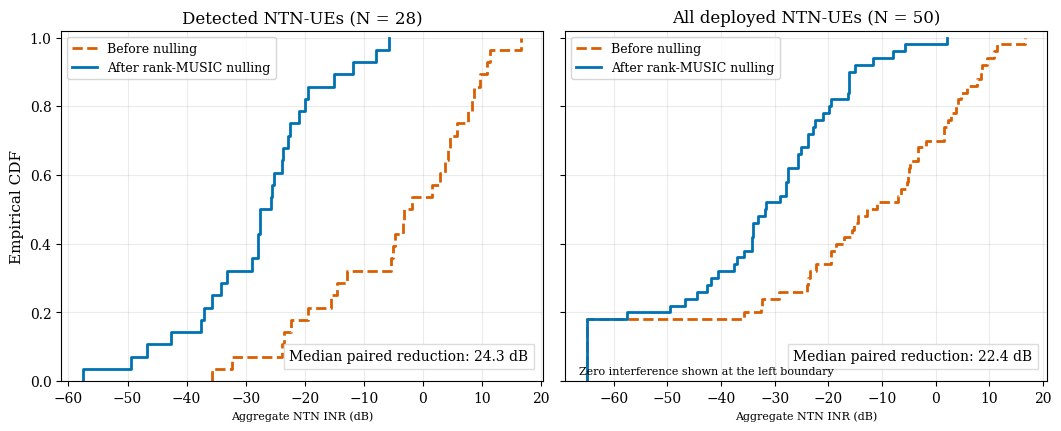

In [6]:
ntn_cdf_figure = map2.plot_ntn_inr_cdf(snapshot, result_dir)
plt.show()


## 6A. Radio-map physics and sampling controls

Run Sections 1–5 once to create `SceneConfig` and `snapshot`, then run **6A → 6B → 7A → 7B → 7C**. For each surface-height or sampling trial, edit and run **6A**, then run **6B → 7C**. For rendering-only adjustments, edit and run **7A**, then run **7C**. Deployment, MUSIC, beam weights, and terminal CDF stay fixed. Each solve and render is saved in its own timestamped directory under this snapshot.

- **Planar measurement height** is `fallback_center[2]`, currently 1 m above the flat ground at z=0. XY center/size cover the ground slab; `radiomap_cell_size` now sets the actual planar bin size.

Previous terrain-mode note, retained for reference:
> - **Terrain offset** raises the measurement mesh relative to the terrain; a 1.5 m surface can lie below roofs. `fallback_center[2]` is an absolute world z and applies only to planar maps. This scene has terrain around z=0–140 m, so a low absolute plane can lie underground; use terrain mode for a constant offset above local ground.

- **Samples per TX** controls the actual launch lattice in one native solver call. Sionna launches deterministic Fibonacci directions: repeating an equal-size solve with different seeds does not densify the direct-ray grid. The old repeated-batch averaging is removed.
- **Cell size** controls planar bins only. Terrain-map bins are the existing mesh triangles; changing `cell_size` cannot coarsen that mesh.
- **Camera height**, render resolution, and image samples belong to Section 7 and do not improve radio-ray coverage.

Native Sionna renders zero-power cells transparently. Empty-looking areas can also be hidden by buildings. Zero sampled power alone does not prove physical zero interference. Raising the measurement surface changes the evaluated location, including propagation; it is not just a visual fix.

The radio-map controls match `map.ipynb`, including its native scene thermal-noise denominator. The terminal CDF retains the main experiment's VSAT noise figure. The 50-terminal rank-MUSIC experiment and its before/after beam choices are retained.


In [ ]:
# GPU compromise: denser rays with a 10 m grid to limit map storage.
# Edit this cell, then rerun 6B -> 7C. Initialize 7A/7B once.
# radiomap_surface = "terrain"  # "terrain" or "plane".
radiomap_surface = "plane"  # "terrain" or "plane".
radiomap_terrain_name = "terrain"
radiomap_terrain_z_offset = 1.0  # Used only in terrain mode; plane mode uses fallback_center[2].
# radiomap_cell_size = (1, 1)  # Ignored by Sionna for terrain meshes, as in map.ipynb.
radiomap_cell_size = (10, 10)  # Planar grid resolution in meters; previous (1, 1) uses 100x the cells.
radiomap_max_depth = 3  # Independent of the LOS-only NTN channel depth.
radiomap_samples_per_tx = 10**9  # Per TX: 12 sectors launch 12 billion rays per beam set.
radiomap_max_rays_per_call = 10**9  # One TX per call at 1B rays/TX; avoid uint32 overflow.
radiomap_seed = None  # Generate one fresh seed per solve, shared before/after.

# fallback_center = [0.0, 0.0, 1.5]
# fallback_size = [
#     float(SceneConfig.extent[1] - SceneConfig.extent[0]),
#     float(SceneConfig.extent[3] - SceneConfig.extent[2]),
# ]
# Planar measurement surface: 1 m above the flat ground, below more low structures.
fallback_center = [-3.292236328125, 3.007080078125, 1.0]
fallback_size = [10044.43798828125, 10082.26025390625]

# Match the native inr_ntn denominator in map.ipynb. The terminal CDF uses N0_vsat.
radiomap_noise_power = float(SceneConfig.scene.thermal_noise_power.numpy().item())
# Explicit versions of the native solver defaults used by map.ipynb.
radiomap_propagation = dict(max_depth=radiomap_max_depth, los=True,
    specular_reflection=True, diffuse_reflection=True, refraction=True,
    diffraction=True, edge_diffraction=False)


## 6B. Solve both maps for the current snapshot

Trace one complete lattice per TX, splitting transmitters into batches under the single-call ray budget. Before/after use the same batch schedule and interaction seeds. At one billion rays/TX this means twelve calls per beam set.


In [ ]:
# Native solver code is intentionally inline for interactive experiments.
import drjit as dr
import mitsuba as mi
from sionna.rt import RadioMapSolver, MeshRadioMap, PlanarRadioMap, transform_mesh

if not mi.variant().startswith("cuda_"):
    raise RuntimeError("Radio maps require CUDA here. Restart Python (sionna22) and run the import cell first.")
# Release maps from a previous solve before allocating either new beam set.
for _old_name in ("radio_maps", "solved", "reference_map", "centers"):
    globals().pop(_old_name, None)
gc.collect()
dr.flush_malloc_cache()


def with_aggregate_inr(radio_map, noise_power):
    """Expose sum(TX RSS)/N for both mesh and planar maps, without package edits."""
    class AggregateRadioMap(type(radio_map)):
        @property
        def inr_ntn(self):
            return dr.sum(self.rss, axis=0) / self._map2_noise_power

        def transmitter_radio_map(self, metric="path_gain", tx=None):
            if metric == "inr_ntn":
                return self.inr_ntn
            return super().transmitter_radio_map(metric=metric, tx=tx)

    adapted = object.__new__(AggregateRadioMap)
    adapted.__dict__.update(radio_map.__dict__)
    adapted._map2_noise_power = float(noise_power)
    return adapted


def solve_radiomap_batched(scene, solver, precoding, *, surface_kwargs,
                          samples_per_tx, max_rays_per_call, seed,
                          propagation, label="radio map"):
    """Trace one full lattice per TX; concatenate independent TX maps in order."""
    transmitters = list(scene.transmitters.values())
    count = len(transmitters)
    batch_size = min(count, int(max_rays_per_call) // int(samples_per_tx))
    if batch_size < 1:
        raise ValueError("One TX exceeds max_rays_per_call; increase that budget or reduce samples_per_tx.")
    if np.shape(precoding)[0] != count:
        raise ValueError("Precoding rows must match the original transmitter order.")

    def run_batch(start, stop, batch_seed):
        weights = (mi.TensorXf(np.ascontiguousarray(precoding[start:stop].real)),
                   mi.TensorXf(np.ascontiguousarray(precoding[start:stop].imag)))
        result = solver(scene, **surface_kwargs, precoding_vec=weights,
            samples_per_tx=int(samples_per_tx), seed=int(batch_seed), **propagation)
        dr.eval(result.path_gain)
        return result

    if batch_size == count:
        return run_batch(0, count, seed)

    gains = []
    try:
        for tx in transmitters:
            scene.remove(tx.name)
        for batch_index, start in enumerate(range(0, count, batch_size)):
            stop = min(start + batch_size, count)
            selected = transmitters[start:stop]
            for tx in selected:
                scene.add(tx)
            batch_seed = (int(seed) + batch_index) % (2**32)
            print(f"  {label}: TX {start+1}-{stop}/{count}, "
                  f"{samples_per_tx*(stop-start):,} rays, seed={batch_seed}", flush=True)
            batch_map = run_batch(start, stop, batch_seed)
            # Move finished results to the host before allocating the next batch.
            gains.append(batch_map.path_gain.numpy().copy())
            del batch_map
            for tx in selected:
                scene.remove(tx.name)
            gc.collect()
            dr.flush_malloc_cache()
    finally:
        # Preserve every transmitter object and insertion order, including on errors.
        for name in list(scene.transmitters):
            scene.remove(name)
        for tx in transmitters:
            scene.add(tx)

    if "measurement_surface" in surface_kwargs:
        combined = MeshRadioMap(scene, surface_kwargs["measurement_surface"])
    else:
        combined = PlanarRadioMap(scene, **surface_kwargs)
    full_gain = np.concatenate(gains, axis=0)
    if tuple(full_gain.shape) != tuple(combined.path_gain.shape):
        raise RuntimeError("Batched path-gain dimensions do not match the restored scene.")
    # Sionna RT 2.2 stores both planar and mesh path gains in this native tensor.
    # Each TX map is already normalized by its own full launch count. Concatenate,
    # do not average or rescale; the existing INR adapter then sums TX RSS / noise.
    combined._pathgain_map = mi.TensorXf(np.ascontiguousarray(full_gain))
    dr.eval(combined.path_gain)
    return combined


if not isinstance(radiomap_samples_per_tx, (int, np.integer)) or radiomap_samples_per_tx < 2:
    raise ValueError("samples_per_tx must be an integer >= 2.")
if (not isinstance(radiomap_max_rays_per_call, (int, np.integer))
        or not 1 <= radiomap_max_rays_per_call <= 2**32 - 1):
    raise ValueError("max_rays_per_call must be an integer in [1, 2**32-1].")
if radiomap_samples_per_tx > radiomap_max_rays_per_call:
    raise ValueError("samples_per_tx exceeds the single-call ray budget.")
if radiomap_noise_power <= 0:
    raise ValueError("Radio-map noise power must be positive.")

radiomap_scene = SceneConfig.scene
if radiomap_surface == "terrain":
    names = [name for name in radiomap_scene.objects if name.lower() == radiomap_terrain_name.lower()]
    if len(names) != 1:
        raise ValueError(f"Expected one terrain object; found {names}.")
    terrain = radiomap_scene.objects[names[0]].clone(as_mesh=True)
    transform_mesh(terrain, translation=[0, 0, float(radiomap_terrain_z_offset)])
    surface_kwargs = dict(measurement_surface=terrain, cell_size=radiomap_cell_size)
elif radiomap_surface == "plane":
    if np.any(np.asarray(radiomap_cell_size) <= 0):
        raise ValueError("Planar cell dimensions must be positive.")
    surface_kwargs = dict(center=list(fallback_center), size=list(fallback_size),
        orientation=[0., 0., 0.], cell_size=radiomap_cell_size)
else:
    raise ValueError("radiomap_surface must be 'terrain' or 'plane'.")

radiomap_num_tx = len(radiomap_scene.transmitters)
radiomap_tx_batch_size = min(radiomap_num_tx, radiomap_max_rays_per_call // radiomap_samples_per_tx)
radiomap_batch_count = (radiomap_num_tx + radiomap_tx_batch_size - 1) // radiomap_tx_batch_size
print(f"TX batching: {radiomap_tx_batch_size} TX/call, {radiomap_batch_count} calls per beam set.")
print(f"Backend: {mi.variant()}; total rays per beam set: {radiomap_num_tx * radiomap_samples_per_tx:,}")
if radiomap_surface == "plane":
    cells_xy = np.ceil(np.asarray(fallback_size) / np.asarray(radiomap_cell_size)).astype(np.int64)
    pair_storage_gib = 2 * radiomap_num_tx * int(np.prod(cells_xy)) * 4 / 2**30
    print(f"Grid: {cells_xy[0]} x {cells_xy[1]}; two float32 path-gain maps alone: {pair_storage_gib:.3f} GiB (solver/rendering need more).")

# Resolve once so both beam sets use the same random interactions.
radiomap_effective_seed = (int(np.random.SeedSequence().generate_state(1)[0])
                          if radiomap_seed is None else int(radiomap_seed))

# Each solve has its own directory so height/density trials can be compared later.
radiomap_trial_dir = result_dir / "radiomap_trials" / datetime.now(result_timezone).strftime("%Y%m%d_%H%M%S_%f%Z")
radiomap_trial_dir.mkdir(parents=True, exist_ok=False)
radiomap_run = dict(surface=radiomap_surface, terrain_name=radiomap_terrain_name,
    terrain_z_offset=radiomap_terrain_z_offset, fallback_center=fallback_center,
    fallback_size=fallback_size, reference_notebook="map.ipynb",
    cell_size=radiomap_cell_size, samples_per_tx=radiomap_samples_per_tx,
    backend=mi.variant(), sionna_rt_version=sionna_rt.__version__, python_executable=sys.executable,
    seed=radiomap_effective_seed, requested_seed=radiomap_seed,
    noise_power_w=radiomap_noise_power, propagation=dict(radiomap_propagation),
    launch_method="One full native Fibonacci lattice per TX; concatenate TX maps across batches",
    max_rays_per_call=radiomap_max_rays_per_call, tx_per_batch=radiomap_tx_batch_size,
    calls_per_beam_set=radiomap_batch_count,
    batch_seeds=[(radiomap_effective_seed+i) % (2**32) for i in range(radiomap_batch_count)],
    power_model="Native spatially averaged power, isotropic receiver",
    terminal_validation="The terminal INR CDF uses LOS-only VSAT channels; this radio map includes multipath")
map2.save_json(radiomap_trial_dir / "solve_settings.json", radiomap_run)

solver = map2.make_radiomap_solver()
radio_maps = {}
for tag in ("before", "after"):
    beams = snapshot[f"beams_{tag}"]
    precoding = ncu.build_precoding_matrix_from_tx_beams(
        list(radiomap_scene.transmitters), dict(enumerate(beams)),
        nsect=int(SceneConfig.nsect), apply_conjugate=True)
    np.testing.assert_allclose(np.linalg.norm(precoding, axis=1), 1., atol=1e-6)
    print(f"Solving {tag}: {radiomap_samples_per_tx:,} launch directions per TX", flush=True)
    solved = solve_radiomap_batched(radiomap_scene, solver, precoding,
        surface_kwargs=surface_kwargs, samples_per_tx=int(radiomap_samples_per_tx),
        max_rays_per_call=int(radiomap_max_rays_per_call), seed=radiomap_effective_seed,
        propagation=radiomap_propagation, label=tag)
    radio_maps[tag] = with_aggregate_inr(solved, radiomap_noise_power)
    del solved
    gc.collect()
    dr.flush_malloc_cache()

reference_map = radio_maps["before"]
centers = reference_map.cell_centers.numpy()
radiomap_cell_centers = centers.T if isinstance(reference_map, MeshRadioMap) else centers.reshape(-1, 3)
radiomap_values = {key: value.inr_ntn.numpy() for key, value in radio_maps.items()}
radiomap_stats = {}
for tag, values in radiomap_values.items():
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise RuntimeError(f"Invalid INR values in {tag} radio map.")
    zero = int(np.count_nonzero(values == 0))
    radiomap_stats[tag] = dict(cells=values.size, zero_cells=zero, zero_cell_fraction=zero/values.size)
    print(f"{tag}: {zero:,}/{values.size:,} cells have zero sampled power ({zero/values.size:.1%}).")
np.savez_compressed(radiomap_trial_dir / "map2_sionna_radiomap.npz",
    inr_before=radiomap_values["before"], inr_after=radiomap_values["after"],
    cell_centers=radiomap_cell_centers)
map2.save_json(radiomap_trial_dir / "sampling_summary.json", radiomap_stats)
print(f"Trial saved to: {radiomap_trial_dir.resolve()}")


## 7A. Rendering controls

Change these controls and rerun **7C**. Run **7B** once, or again after editing marker/projection helpers. This reuses `radio_maps` from the most recent solve.

Defaults, marker colors/radii, legend, shared auto-contrast, and final figure layout follow `map.ipynb`. The render uses the explicit camera position and look-at point, with no extra extent-based crop.


In [9]:
# GPU preview resolution; composition settings match map.ipynb.
# Edit this cell, then rerun 7C. Radio-map solving and beamforming are reused.
radiomap_metric = "inr_ntn"
radiomap_render_resolution = (2000, 2000)  # Previous 10000x10000 has 25x more pixels.
radiomap_render_num_samples = 16
radiomap_vmin = -25
radiomap_vmax = 45
radiomap_use_auto_contrast = True
radiomap_auto_contrast_percentiles = (2.0, 98.0)
radiomap_camera_pos = [0, 0, 10000]
radiomap_camera_look_at = [0, 0, 0]
radiomap_fov = 60
radiomap_cmap = "viridis"
radiomap_clip_at = None

# BS triangle vertices follow actual array boresights; NTN uses small screen-space crosses.
radiomap_ntn_color = (1.0, 0.0, 1.0)  # Shared by detected NTN markers in radiomap and geographic layout.
layout_undetected_ntn_color = "#333333"  # All undetected NTN UEs are shown in the geographic layout.
radiomap_bs_display_radius = 110  # World-space distance from BS to each triangle vertex (m).
radiomap_tn_marker_size = 6.5  # Points; fill matches the serving BS, with dark outlines.
radiomap_tn_marker_edgecolor = (0.10, 0.10, 0.10)
radiomap_tn_marker_linewidth = 1.0
radiomap_ntn_marker_size = 6.0  # Matplotlib points in the rendered panel.
radiomap_ntn_marker_linewidth = 1.3
radiomap_legend_symbol_color = "#404040"  # One neutral symbol per device class in the legend.
radiomap_legend_loc = "upper left"
radiomap_legend_bbox_to_anchor = (0.105, 0.945)  # Clear the TN marker near the upper-left corner.
radiomap_legend_framealpha = 0.48
radiomap_legend_fontsize = 10
radiomap_panel_dpi = 180

# Tight combined and standalone figures, each saved once in the run directory.
radiomap_figure_width_inches = 3.35
radiomap_figure_dpi = 200
radiomap_output_dpi = 400
radiomap_caption_height_inches = 0.14
radiomap_panel_gap_inches = 0.05
# One shared horizontal legend above the combined before/after figure.
radiomap_combined_legend_height_inches = 0.24
radiomap_combined_legend_fontsize = 6.5
radiomap_combined_legend_marker_scale = 0.55
radiomap_colorbar_geometry = dict(gap_inches=0.060, width_inches=0.055,
    tick_space_inches=0.22, y_fraction=0.025, height_fraction=0.93)
radiomap_colorbar_fontsize = 6
radiomap_label_fontsize = 6

# Sector boundaries sit below the BS triangles and NTN crosses.
radiomap_show_cell_boundaries = False  # Hide rectangular cell edges, including the central white cross.
radiomap_boundary_height = 1.5
radiomap_bs_colors = tuple(map2.BS_COLORS)  # One color per BS: triangle, paired TN fills, dashed boundaries.


## 7B. Editable camera projection and overlay helpers


In [10]:
import matplotlib.patheffects as pe
from sionna.rt import Camera
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Polygon
from matplotlib.path import Path as MarkerPath
from sionna.rt.utils import rotation_matrix


def _project_to_camera(points, camera, fov, resolution):
    """Project world coordinates to the same perspective camera as scene.render."""
    matrix = np.asarray(camera.world_transform.matrix.numpy()).squeeze()
    points = np.atleast_2d(points)
    local = np.c_[points, np.ones(len(points))] @ np.linalg.inv(matrix).T
    scale = 2*np.tan(np.deg2rad(fov/2))*local[:, 2]
    width, height = resolution
    return np.c_[width*(.5-local[:, 0]/scale), height*.5-width*local[:, 1]/scale]


def _render_sector_boundaries(ax, config, camera, fov, resolution):
    project = lambda xyz: _project_to_camera(xyz, camera, fov, resolution)
    rectangles = np.asarray(config.tn_sampler.rectangles)
    if radiomap_show_cell_boundaries:
        for rect in rectangles:
            xmin, xmax, ymin, ymax = rect
            xy = np.array([[xmin,ymin], [xmax,ymin], [xmax,ymax], [xmin,ymax], [xmin,ymin]])
            pixels = project(np.c_[xy, np.full(5, radiomap_boundary_height)])
            ax.plot(*pixels.T, color="white", lw=.7, alpha=.75, zorder=4)
    for b, segment in map2.sector_boundary_segments(config.tx_pos, rectangles, config.tn_drop_yaw_rad):
        # The geographic partition lies on the ground, independent of BS height.
        pixels = project(np.c_[segment, [radiomap_boundary_height, radiomap_boundary_height]])
        line, = ax.plot(*pixels.T, color=radiomap_bs_colors[b], lw=1.1, linestyle=(0,(6,4)), zorder=5)
        line.set_path_effects([pe.Stroke(linewidth=2.1, foreground="white", alpha=.9), pe.Normal()])




def _bs_triangle_geometry(config, radius):
    """Use each sector's actual local +x array axis, transformed into world space."""
    if int(config.nsect) != 3:
        raise ValueError("The BS triangle symbol requires three sectors per BS.")
    boresights = []
    for b, position in enumerate(config.tx_pos):
        directions = []
        for sector in range(3):
            tx = config.scene.transmitters[f"tx-{b}-{sector}"]
            direction = rotation_matrix(tx.orientation) @ mi.Vector3f(1., 0., 0.)
            directions.append(direction.numpy().reshape(3))
        boresights.append(directions)
    boresights = np.asarray(boresights)
    vertices = np.asarray(config.tx_pos)[:, None, :] + float(radius)*boresights
    return vertices, boresights


def _bs_legend_marker(projected_vertices):
    vertices = np.asarray(projected_vertices) - np.mean(projected_vertices, axis=0)
    vertices[:, 1] *= -1  # Image coordinates point down; marker coordinates point up.
    return MarkerPath(np.vstack([vertices, vertices[0]]), closed=True)


def _render_device_symbols(ax, bs_triangles_px, tn_pos, tn_bs_index, ntn_pos, camera, fov, resolution):
    limits = ax.get_xlim(), ax.get_ylim()
    for b, vertices in enumerate(bs_triangles_px):
        ax.add_patch(Polygon(vertices, closed=True, facecolor=radiomap_bs_colors[b],
            edgecolor="white", linewidth=.6, zorder=8))
    if len(tn_pos):
        pixels = _project_to_camera(tn_pos, camera, fov, resolution)
        # Use the accepted serving-BS association, not nearest-BS geometry.
        for b in range(len(bs_triangles_px)):
            selected = np.asarray(tn_bs_index) == b
            if not np.any(selected):
                continue
            dots, = ax.plot(*pixels[selected].T, linestyle="None", marker="o",
                markerfacecolor=radiomap_bs_colors[b], markeredgecolor=radiomap_tn_marker_edgecolor,
                markersize=radiomap_tn_marker_size,
                markeredgewidth=radiomap_tn_marker_linewidth, zorder=9)
            dots.set_path_effects([pe.Stroke(linewidth=2.0, foreground="white"), pe.Normal()])
    if len(ntn_pos):
        pixels = _project_to_camera(ntn_pos, camera, fov, resolution)
        ax.plot(*pixels.T, linestyle="None", marker="x", color=radiomap_ntn_color,
            markersize=radiomap_ntn_marker_size,
            markeredgewidth=radiomap_ntn_marker_linewidth, zorder=9)
    ax.set_xlim(limits[0])
    ax.set_ylim(limits[1])


def _metric_values_db_from_rm(radio_map, metric, eps=1e-30):
    metric_tensor = getattr(radio_map, metric)
    metric_values = np.asarray(metric_tensor, dtype=np.float64)
    metric_values = np.real(metric_values).reshape(-1)
    metric_values = metric_values[np.isfinite(metric_values)]
    metric_values = metric_values[metric_values > float(eps)]
    if metric_values.size == 0:
        return np.array([], dtype=np.float64)
    return 10.0 * np.log10(np.maximum(metric_values, float(eps)))


def _resolve_shared_rm_limits(
    radio_maps,
    metric,
    *,
    rm_vmin=None,
    rm_vmax=None,
    auto_contrast=False,
    auto_contrast_percentiles=(5.0, 95.0),
    auto_contrast_eps=1e-30,
):
    db_values = [
        _metric_values_db_from_rm(radio_map, metric, eps=auto_contrast_eps)
        for radio_map in radio_maps
    ]
    db_values = [values for values in db_values if values.size > 0]

    if not db_values:
        vmin = 0.0 if rm_vmin is None else float(rm_vmin)
        vmax = 1.0 if rm_vmax is None else float(rm_vmax)
        if vmax <= vmin:
            vmax = vmin + 1.0
        print(f"shared color range for {metric}: [{vmin:.2f}, {vmax:.2f}] dB (fallback)")
        return float(vmin), float(vmax)

    stacked = np.concatenate(db_values, axis=0)

    if auto_contrast:
        p_low = float(auto_contrast_percentiles[0])
        p_high = float(auto_contrast_percentiles[1])
        vmin = float(np.percentile(stacked, p_low))
        vmax = float(np.percentile(stacked, p_high))
        if vmax <= vmin:
            vmax = vmin + 1.0
        print(
            f"shared auto contrast for {metric}: "
            f"p{p_low:.1f}={vmin:.2f} dB, p{p_high:.1f}={vmax:.2f} dB"
        )
        return vmin, vmax

    vmin = float(np.min(stacked)) if rm_vmin is None else float(rm_vmin)
    vmax = float(np.max(stacked)) if rm_vmax is None else float(rm_vmax)
    if vmax <= vmin:
        vmax = vmin + 1.0
    print(f"shared color range for {metric}: [{vmin:.2f}, {vmax:.2f}] dB")
    return vmin, vmax


def _draw_radiomap_legend(
    ax,
    overlay_bs_pos,
    overlay_tn_pos,
    overlay_ntn_pos,
    ntn_color,
    *,
    bs_marker=">",
    loc="upper left",
    bbox_to_anchor=(0.045, 0.965),
    framealpha=0.48,
    fontsize=6.5,
    ncols=1,
    frameon=True,
    marker_scale=1.0,
):
    legend_handles = []

    if overlay_bs_pos is not None and len(overlay_bs_pos) > 0:
        legend_handles.append(
            Line2D([0], [0], marker=bs_marker, linestyle="None", markersize=8*marker_scale,
                markerfacecolor=radiomap_legend_symbol_color,
                markeredgecolor="none", markeredgewidth=0))

    if overlay_tn_pos is not None and len(overlay_tn_pos) > 0:
        legend_handles.append(
            Line2D([0], [0], marker="o", linestyle="None", markersize=radiomap_tn_marker_size*marker_scale,
                markerfacecolor=radiomap_legend_symbol_color,
                markeredgecolor=radiomap_tn_marker_edgecolor,
                markeredgewidth=radiomap_tn_marker_linewidth*marker_scale))

    if overlay_ntn_pos is not None and len(overlay_ntn_pos) > 0:
        legend_handles.append(
            Line2D(
                [0], [0],
                marker="x",
                linestyle="None",
                markersize=radiomap_ntn_marker_size*marker_scale,
                markerfacecolor=ntn_color,
                markeredgecolor=ntn_color,
                markeredgewidth=radiomap_ntn_marker_linewidth*marker_scale,
                label="NTN-UE",
            )
        )

    if legend_handles:
        labels = []
        if overlay_bs_pos is not None and len(overlay_bs_pos):
            labels.append("BaseStation")
        if overlay_tn_pos is not None and len(overlay_tn_pos):
            labels.append("TN-UE")
        if overlay_ntn_pos is not None and len(overlay_ntn_pos):
            labels.append("NTN-UE")
        legend = ax.legend(
            handles=legend_handles, labels=labels,
            handlelength=1.2, numpoints=1,
            loc=loc,
            bbox_to_anchor=bbox_to_anchor,
            bbox_transform=ax.transAxes if hasattr(ax, "transAxes") else ax.transFigure,
            ncols=ncols,
            frameon=frameon,
            facecolor="white",
            edgecolor="black",
            framealpha=framealpha,
            borderpad=0.30,
            labelspacing=0.55,
            handletextpad=0.34,
            fontsize=fontsize,
        )
        legend.set_zorder(20)
        return legend


## 7C. Render the existing maps

This cell contains the actual `scene.render` calls and figure layout. It never reruns deployment, MUSIC, or `RadioMapSolver`.


In [ ]:
# Final figures live only in result_dir. Each redraw archives settings separately.
import io
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

radiomap_render_dir = radiomap_trial_dir / "renders" / datetime.now(result_timezone).strftime("%Y%m%d_%H%M%S_%f%Z")
radiomap_render_dir.mkdir(parents=True, exist_ok=False)
shared_vmin, shared_vmax = _resolve_shared_rm_limits(
    list(radio_maps.values()), radiomap_metric,
    rm_vmin=radiomap_vmin, rm_vmax=radiomap_vmax,
    auto_contrast=radiomap_use_auto_contrast,
    auto_contrast_percentiles=radiomap_auto_contrast_percentiles)

camera = Camera(position=list(radiomap_camera_pos), look_at=list(radiomap_camera_look_at))
overlay_bs_pos = np.asarray(SceneConfig.tx_pos)
overlay_tn_pos = np.asarray(SceneConfig.tn_pos)
overlay_tn_bs_index = np.asarray(SceneConfig.tn_bs_index, dtype=int)
if overlay_tn_bs_index.shape != (len(overlay_tn_pos),):
    raise ValueError("Each TN marker needs its accepted serving-BS index.")
if (len(radiomap_bs_colors) < len(overlay_bs_pos)
        or np.any(overlay_tn_bs_index < 0)
        or np.any(overlay_tn_bs_index >= len(overlay_bs_pos))):
    raise ValueError("Invalid serving-BS indices or insufficient BS colors.")

overlay_ntn_pos = np.asarray(SceneConfig.rx_ntn_pos)[snapshot["detected_idx"]]
bs_triangle_vertices, bs_array_boresights = _bs_triangle_geometry(
    SceneConfig, radiomap_bs_display_radius)
bs_triangles_px = [_project_to_camera(vertices, camera, radiomap_fov, radiomap_render_resolution)
                   for vertices in bs_triangle_vertices]
bs_legend_marker = _bs_legend_marker(bs_triangles_px[0])


def _capture_radiomap_panel(figure):
    """Keep intermediate raster panels in memory, not as duplicate output files."""
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=radiomap_panel_dpi,
                   bbox_inches="tight", pad_inches=0.0, facecolor="white")
    buffer.seek(0)
    return plt.imread(buffer, format="png")


panel_variants = {}
for key in ("before", "after"):
    print(f"Rendering {key} at {radiomap_render_resolution[0]} x {radiomap_render_resolution[1]} pixels...", flush=True)
    panel_fig = SceneConfig.scene.render(camera=camera, radio_map=radio_maps[key],
        resolution=tuple(radiomap_render_resolution), fov=float(radiomap_fov),
        num_samples=int(radiomap_render_num_samples), clip_at=radiomap_clip_at,
        show_devices=False, rm_metric=radiomap_metric, rm_tx=0, rm_cmap=radiomap_cmap,
        rm_vmin=shared_vmin, rm_vmax=shared_vmax, rm_show_color_bar=False)
    panel_ax = panel_fig.axes[0]
    _render_sector_boundaries(panel_ax, SceneConfig, camera, radiomap_fov, radiomap_render_resolution)
    _render_device_symbols(panel_ax, bs_triangles_px, overlay_tn_pos, overlay_tn_bs_index, overlay_ntn_pos, camera,
                           radiomap_fov, radiomap_render_resolution)
    plain = _capture_radiomap_panel(panel_fig)
    _draw_radiomap_legend(panel_ax, overlay_bs_pos, overlay_tn_pos, overlay_ntn_pos,
        radiomap_ntn_color,
        bs_marker=bs_legend_marker, loc=radiomap_legend_loc, bbox_to_anchor=radiomap_legend_bbox_to_anchor,
        framealpha=radiomap_legend_framealpha, fontsize=radiomap_legend_fontsize)
    panel_variants[key] = dict(plain=plain, legend=_capture_radiomap_panel(panel_fig))
    plt.close(panel_fig)

# The camera image itself includes a white surround. Use one common tight crop
# for all variants, preserving map alignment and every visible edge marker.
all_images = [img for variants in panel_variants.values() for img in variants.values()]
if len({img.shape for img in all_images}) != 1:
    raise RuntimeError("Before/after render dimensions differ; cannot apply a common crop.")
content = np.zeros(all_images[0].shape[:2], dtype=bool)
for img in all_images:
    nonwhite = np.any(img[..., :3] < .995, axis=-1)
    if img.shape[-1] == 4:
        nonwhite &= img[..., 3] > .01
    content |= nonwhite
rows, cols = np.nonzero(content)
if not len(rows):
    raise RuntimeError("Rendered radio maps contain no visible content.")
crop_box = [int(cols.min()), int(rows.min()), int(cols.max()+1), int(rows.max()+1)]
x0, y0, x1, y1 = crop_box
for variants in panel_variants.values():
    for variant in variants:
        variants[variant] = variants[variant][y0:y1, x0:x1]


def _save_radiomap_composition(images, labels, stem, *, legend_above=False):
    """Export tightly packed maps with adjacent, frameless, shared-scale bars."""
    geometry = radiomap_colorbar_geometry
    width = float(radiomap_figure_width_inches)
    map_width = width - geometry["gap_inches"] - geometry["width_inches"] - geometry["tick_space_inches"]
    if map_width <= 0:
        raise ValueError("Colorbar layout leaves no room for the map.")
    map_height = map_width * images[0].shape[0] / images[0].shape[1]
    caption = float(radiomap_caption_height_inches)
    panel_gap = float(radiomap_panel_gap_inches)
    legend_height = float(radiomap_combined_legend_height_inches) if legend_above else 0.0
    height = len(images)*(map_height + caption) + (len(images)-1)*panel_gap + legend_height
    figure = plt.figure(figsize=(width, height), dpi=radiomap_figure_dpi)
    mappable = ScalarMappable(norm=Normalize(vmin=shared_vmin, vmax=shared_vmax),
                             cmap=plt.get_cmap(radiomap_cmap))
    for index, (img, label) in enumerate(zip(images, labels)):
        top = height - legend_height - index*(map_height + caption + panel_gap)
        bottom = top - map_height
        ax = figure.add_axes([0., bottom/height, map_width/width, map_height/height])
        ax.imshow(img)
        ax.set_axis_off()
        cax = figure.add_axes([(map_width + geometry["gap_inches"])/width,
            (bottom + geometry["y_fraction"]*map_height)/height,
            geometry["width_inches"]/width, geometry["height_fraction"]*map_height/height])
        cbar = figure.colorbar(mappable, cax=cax, orientation="vertical")
        cbar.outline.set_visible(False)
        for spine in cbar.ax.spines.values():
            spine.set_visible(False)
        cbar.ax.set_title("dB", fontsize=radiomap_colorbar_fontsize, pad=2)
        cbar.ax.tick_params(labelsize=radiomap_colorbar_fontsize, pad=1, length=2)
        figure.text(.5*map_width/width, (bottom-.5*caption)/height, label,
                    ha="center", va="center", fontsize=radiomap_label_fontsize)
    if legend_above:
        _draw_radiomap_legend(figure, overlay_bs_pos, overlay_tn_pos, overlay_ntn_pos,
            radiomap_ntn_color, bs_marker=bs_legend_marker,
            loc="upper center", bbox_to_anchor=(.5*map_width/width, 1.0),
            fontsize=radiomap_combined_legend_fontsize, ncols=3, frameon=False,
            marker_scale=radiomap_combined_legend_marker_scale)
    for extension in ("png", "pdf"):
        figure.savefig(result_dir / f"{stem}.{extension}", dpi=radiomap_output_dpi,
                       bbox_inches="tight", pad_inches=0.0, facecolor="white")
    return figure


fig = _save_radiomap_composition(
    [panel_variants["before"]["plain"], panel_variants["after"]["plain"]],
    ["(a) Before Nulling", "(b) After Nulling"], "map2_inr_before_after", legend_above=True)
for key, label in (("before", "Before Nulling"), ("after", "After Nulling")):
    single = _save_radiomap_composition([panel_variants[key]["legend"]], [label], f"map2_inr_{key}")
    plt.close(single)

output_files = [str((result_dir / f"map2_inr_{tag}.{extension}").resolve())
                for tag in ("before_after", "before", "after") for extension in ("png", "pdf")]
map2.save_json(radiomap_render_dir / "map2_render_settings.json", dict(
    reference_notebook="map2.ipynb", metric=radiomap_metric,
    limits_db=[shared_vmin, shared_vmax], requested_limits_db=[radiomap_vmin, radiomap_vmax],
    auto_contrast=radiomap_use_auto_contrast, percentiles=radiomap_auto_contrast_percentiles,
    resolution=radiomap_render_resolution, samples_per_pixel=radiomap_render_num_samples,
    camera_pos=radiomap_camera_pos, camera_look_at=radiomap_camera_look_at, fov_deg=radiomap_fov,
    figure_width_inches=radiomap_figure_width_inches, cmap=radiomap_cmap, clip_at=radiomap_clip_at,
    common_crop_box_pixels=crop_box, crop_white_surround=True, export_pad_inches=0,
    output_files=output_files, single_output_location=str(result_dir.resolve()),
    marker_colors=dict(bs=list(radiomap_bs_colors),
        tn=[radiomap_bs_colors[int(b)] for b in overlay_tn_bs_index], ntn=radiomap_ntn_color),
    tn_serving_bs_index=overlay_tn_bs_index.tolist(),
    association_color_rule="BS triangle, its paired TN fills, and its sector boundaries share one color",
    marker_styles=dict(
        bs=dict(shape="triangle", vertex_radius_m=radiomap_bs_display_radius,
                orientation="actual array local +x boresights projected through render camera"),
        tn=dict(shape="circle", size_pt=radiomap_tn_marker_size,
                edgecolor=radiomap_tn_marker_edgecolor, linewidth_pt=radiomap_tn_marker_linewidth,
                white_outline_linewidth_pt=2.0),
        ntn=dict(shape="x", size_pt=radiomap_ntn_marker_size, linewidth_pt=radiomap_ntn_marker_linewidth)),
    bs_array_boresights_world=bs_array_boresights.tolist(),
    bs_triangle_vertices_world_m=bs_triangle_vertices.tolist(),
    legend=dict(loc=radiomap_legend_loc, bbox_to_anchor=radiomap_legend_bbox_to_anchor,
        framealpha=radiomap_legend_framealpha, fontsize=radiomap_legend_fontsize,
        labels=["BaseStation", "TN-UE", "NTN-UE"], symbols_per_class=1,
        bs_tn_symbol_color=radiomap_legend_symbol_color),
    combined_legend=dict(location="outside above panels", ncols=3, frameon=False,
        height_inches=radiomap_combined_legend_height_inches,
        fontsize=radiomap_combined_legend_fontsize,
        marker_scale=radiomap_combined_legend_marker_scale),
    panel_dpi=radiomap_panel_dpi, figure_dpi=radiomap_figure_dpi, output_dpi=radiomap_output_dpi,
    colorbar_geometry=radiomap_colorbar_geometry, colorbar_outline=False,
    colorbar_fontsize=radiomap_colorbar_fontsize, label_fontsize=radiomap_label_fontsize,
    caption_height_inches=radiomap_caption_height_inches, panel_gap_inches=radiomap_panel_gap_inches,
    show_cell_boundaries=radiomap_show_cell_boundaries,
    boundary_height=radiomap_boundary_height, sector_colors=radiomap_bs_colors))
plt.show()
print(f"Final figures (one copy each): {result_dir.resolve()}")
print(f"Render settings: {radiomap_render_dir.resolve()}")

# Save the geographic deployment alongside all radiomap figures in this run folder.
layout_figure = plot_detection_layout(
    SceneConfig, snapshot, result_dir, background_path=layout_background,
    bs_vertices=bs_triangle_vertices, bs_colors=radiomap_bs_colors,
    detected_color=radiomap_ntn_color, undetected_color=layout_undetected_ntn_color,
    tn_marker_size=radiomap_tn_marker_size, ntn_marker_size=radiomap_ntn_marker_size,
    ntn_marker_linewidth=radiomap_ntn_marker_linewidth)
plt.show()
